# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [353]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

display(plans.head())
display(users.head())
display(usage.head())

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


In [354]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

display(plans.head())
display(users.head())
display(usage.head())

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


In [355]:
# mostrar las primeras 5 filas de plans

In [356]:
# mostrar las primeras 5 filas de users

In [357]:
# mostrar las primeras 5 filas de usage

**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [358]:
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [359]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [360]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [361]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [362]:
print(usage.isna().sum())
print((usage.isna().mean() * 100).round(2))

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id           0.00
user_id      0.00
type         0.00
date         0.12
duration    55.19
length      44.74
dtype: float64


In [363]:

def accion(p):
    if p < 5:
        return "dejar como nulo o imputar", "menor al 5%"
    if p <= 30:
        return "investigar antes de imputar", "entre 5% y 30%"
    if p <= 80:
        return "dejar como nulos si dependen de otra columna", "proporción alta"
    return "ignorar o eliminar la columna", "más del 80% de nulos"

for nombre, df in [('users', users), ('usage', usage)]:
    for col in df.columns:
        n = int(df[col].isna().sum())
        if n:
            p = n / len(df) * 100
            acc, motivo = accion(p)
            print(f"- `{nombre}.{col}`: {n} nulos ({p:.2f}%). Acción: {acc}. Motivo: {motivo}.")
print("- `plans`: sin nulos (2 filas).")

- `users.city`: 469 nulos (11.72%). Acción: investigar antes de imputar. Motivo: entre 5% y 30%.
- `users.churn_date`: 3534 nulos (88.35%). Acción: ignorar o eliminar la columna. Motivo: más del 80% de nulos.
- `usage.date`: 50 nulos (0.12%). Acción: dejar como nulo o imputar. Motivo: menor al 5%.
- `usage.duration`: 22076 nulos (55.19%). Acción: dejar como nulos si dependen de otra columna. Motivo: proporción alta.
- `usage.length`: 17896 nulos (44.74%). Acción: dejar como nulos si dependen de otra columna. Motivo: proporción alta.
- `plans`: sin nulos (2 filas).


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
* **users:** la columna `[columna]` tiene [n] nulos ([x]%). Acción: [imputar / dejar como nulo], porque [una línea de justificación].

**usage:** `duration` tiene [n] nulos ([x]%) y `length` tiene [n] nulos ([x]%). Acción: dejarlos como nulos, porque corresponden al tipo de registro (ver 3.2) y no son errores.

**plans:** sin nulos (2 filas).
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [364]:
# explorar columnas numéricas de users

- La columna `user_id` ... Haz doble clic en este bloque y escribe qué ves.
- La columna `age` ...

In [365]:
# explorar columnas numéricas de usage

- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe qué ves.
- Las columnas ...

In [366]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']


- La columna `city` ...
- La columna `plan` ...

In [367]:
# explorar columna categórica de usage
usage['type'] # completa el código

0        call
1        text
2        text
3        call
4        call
         ... 
39995    call
39996    call
39997    call
39998    text
39999    call
Name: type, Length: 40000, dtype: object

- La columna `type` ...


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?  

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [368]:
nulos_reg_antes = int(users['reg_date'].isna().sum())
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')
n_reg_nc = int(users['reg_date'].isna().sum()) - nulos_reg_antes
print("No convertibles en reg_date:", n_reg_nc)

No convertibles en reg_date: 0


In [369]:
nulos_date_antes = int(usage['date'].isna().sum())
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')
n_date_nc = int(usage['date'].isna().sum()) - nulos_date_antes
print("No convertibles en date:", n_date_nc)

No convertibles en date: 0


In [370]:
anio_min_valido = 2000
y = users['reg_date'].dt.year
print(y.value_counts().sort_index())
n_reg_fut = int((y > 2024).sum())
n_reg_old = int((y < anio_min_valido).sum())
print(f"En reg_date los años van de {y.min():.0f} a {y.max():.0f}; {n_reg_fut} registros ({n_reg_fut/len(users)*100:.2f}%) tienen año posterior a 2024, {n_reg_old} anterior a {anio_min_valido} y {n_reg_nc} no se pudieron convertir.")


2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64
En reg_date los años van de 2022 a 2026; 40 registros (1.00%) tienen año posterior a 2024, 0 anterior a 2000 y 0 no se pudieron convertir.


En `reg_date`, ... haz doble clic en este bloque y escribe qué ves.

In [371]:
y2 = usage['date'].dt.year
print(y2.value_counts().sort_index())


n_date_fut = int((y2 > 2024).sum())
n_date_old = int((y2 < anio_min_valido).sum())
print(f"En date los años van de {y2.min():.0f} a {y2.max():.0f}; {n_date_fut} registros ({n_date_fut/len(usage)*100:.2f}%) tienen año posterior a 2024, {n_date_old} anterior a {anio_min_valido} y {n_date_nc} no se pudieron convertir.")




2024.0    39950
Name: date, dtype: int64
En date los años van de 2024 a 2024; 0 registros (0.00%) tienen año posterior a 2024, 0 anterior a 2000 y 0 no se pudieron convertir.


En `date`, ... haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [372]:
display(users.describe())
n_users = len(users)
n_age_sent = int((users['age'] == -999).sum())
edades_ok = users.loc[users['age'] != -999, 'age']
print(f"La columna user_id tiene {users['user_id'].nunique()} valores únicos en {n_users} filas ({'sin duplicados' if users['user_id'].is_unique else 'con duplicados'}).")
print(f"La columna age tiene el sentinel -999 en {n_age_sent} filas ({n_age_sent/n_users*100:.2f}%); el resto va de {edades_ok.min():.0f} a {edades_ok.max():.0f} años.")

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


La columna user_id tiene 4000 valores únicos en 4000 filas (sin duplicados).
La columna age tiene el sentinel -999 en 55 filas (1.38%); el resto va de 18 a 79 años.


In [373]:
display(usage.describe())
n_usage = len(usage)
print(f"Las columnas id y user_id son identificadores: id tiene {usage['id'].nunique()} valores únicos en {n_usage} filas y user_id corresponde a {usage['user_id'].nunique()} usuarios distintos.")
print(f"La columna duration va de {usage['duration'].min():.2f} a {usage['duration'].max():.2f} ({int((usage['duration'] < 0).sum())} valores negativos).")
print(f"La columna length va de {usage['length'].min():.0f} a {usage['length'].max():.0f} ({int((usage['length'] < 0).sum())} valores negativos).")

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


Las columnas id y user_id son identificadores: id tiene 40000 valores únicos en 40000 filas y user_id corresponde a 3999 usuarios distintos.
La columna duration va de 0.00 a 120.00 (0 valores negativos).
La columna length va de 0 a 1490 (0 valores negativos).


In [374]:
columnas_user = ['city', 'plan']
for col in columnas_user:
    print(users[col].value_counts(dropna=False), "\n")

n_city_sent = int((users['city'] == '?').sum())
ciudades = sorted(users.loc[users['city'] != '?', 'city'].dropna().unique())
print(f"La columna city tiene el sentinel '?' en {n_city_sent} filas ({n_city_sent/n_users*100:.2f}%); ciudades válidas: {', '.join(ciudades)}.")
print(f"La columna plan tiene {users['plan'].nunique()} categorías: {', '.join(map(str, users['plan'].dropna().unique()))}.")

Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64 

Basico     2595
Premium    1405
Name: plan, dtype: int64 

La columna city tiene el sentinel '?' en 96 filas (2.40%); ciudades válidas: Bogotá, CDMX, Cali, GDL, MTY, Medellín.
La columna plan tiene 2 categorías: Basico, Premium.


In [375]:
columnas_user = ['city', 'plan']
for col in columnas_user:
    print(users[col].value_counts(dropna=False), "\n")

n_city_sent = int((users['city'] == '?').sum())
ciudades = sorted(users.loc[users['city'] != '?', 'city'].dropna().unique())
print(f"La columna city tiene el sentinel '?' en {n_city_sent} filas ({n_city_sent/n_users*100:.2f}%); ciudades válidas: {', '.join(ciudades)}.")
print(f"La columna plan tiene {users['plan'].nunique()} categorías: {', '.join(map(str, users['plan'].dropna().unique()))}.")
print(f"- Sentinels: `age` = -999 en {n_age_sent} filas ({n_age_sent/n_users*100:.2f}%) y `city` = '?' en {n_city_sent} filas ({n_city_sent/n_users*100:.2f}%).")
print("- Acción: reemplazar -999 por la mediana de las edades válidas y '?' por nulo (pd.NA). Las demás columnas no muestran valores inválidos.")

Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64 

Basico     2595
Premium    1405
Name: plan, dtype: int64 

La columna city tiene el sentinel '?' en 96 filas (2.40%); ciudades válidas: Bogotá, CDMX, Cali, GDL, MTY, Medellín.
La columna plan tiene 2 categorías: Basico, Premium.
- Sentinels: `age` = -999 en 55 filas (1.38%) y `city` = '?' en 96 filas (2.40%).
- Acción: reemplazar -999 por la mediana de las edades válidas y '?' por nulo (pd.NA). Las demás columnas no muestran valores inválidos.


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [376]:
nulos_reg_antes = int(users['reg_date'].isna().sum())
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')
n_reg_nc = int(users['reg_date'].isna().sum()) - nulos_reg_antes
print("No convertibles en reg_date:", n_reg_nc)

No convertibles en reg_date: 0


In [377]:
nulos_date_antes = int(usage['date'].isna().sum())
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')
n_date_nc = int(usage['date'].isna().sum()) - nulos_date_antes
print("No convertibles en date:", n_date_nc)

No convertibles en date: 0


Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [378]:
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [379]:
users['city'] = users['city'].replace('?', pd.NA)
print("Nulos en city:", users['city'].isna().sum())
users['city'].value_counts(dropna=False)

Nulos en city: 565


Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [380]:
# Asegurar que las fechas estén en formato fecha (no hace daño si ya lo están)
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

# Si no existe anio_min_valido (el kernel se reinició), se define aquí
anio_min_valido = 2000

fuera_reg = (users['reg_date'].dt.year > 2024) | (users['reg_date'].dt.year < anio_min_valido)
fuera_use = (usage['date'].dt.year > 2024) | (usage['date'].dt.year < anio_min_valido)
n_reg_fuera = int(fuera_reg.sum())
n_date_fuera = int(fuera_use.sum())
users.loc[fuera_reg, 'reg_date'] = pd.NaT
usage.loc[fuera_use, 'date'] = pd.NaT
print("reg_date marcadas como NA:", n_reg_fuera, "| date:", n_date_fuera)
print("Nulos reg_date:", users['reg_date'].isna().sum())

reg_date marcadas como NA: 40 | date: 0
Nulos reg_date: 40


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [381]:
mar_duration = usage.groupby('type')['duration'].apply(lambda s: s.isna().mean() * 100).round(2)
print(mar_duration)

type
call     0.00
text    99.93
Name: duration, dtype: float64


In [382]:
mar_length = usage.groupby('type')['length'].apply(lambda s: s.isna().mean() * 100).round(2)
print(mar_length)

type
call    99.93
text     0.00
Name: length, dtype: float64


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

In [383]:
usage["is_text"] = (usage["type"] == "text").astype(int)
usage["is_call"] = (usage["type"] == "call").astype(int)

In [384]:
usage_agg = usage.groupby('user_id')[['is_text', 'is_call', 'duration']].sum().reset_index()
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


💡Insights: 
- Distribución ...

In [385]:
usage_agg = usage_agg.rename(columns={
    'is_text': 'cant_mensajes',
    'is_call': 'cant_llamadas',
    'duration': 'cant_minutos_llamada'
})
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


💡Insights: 
- ....

In [386]:
user_profile = users.merge(usage_agg, on='user_id', how='left')
cols_uso = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
print("Usuarios sin registros de uso:", int(user_profile['cant_llamadas'].isna().sum()))
user_profile[cols_uso] = user_profile[cols_uso].fillna(0)
user_profile.head(5)

Usuarios sin registros de uso: 1


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


💡Insights: 
- Distribución ...

In [387]:
# Histograma para visualizar la cant_minutos_llamada


💡Insights: 
- ...

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

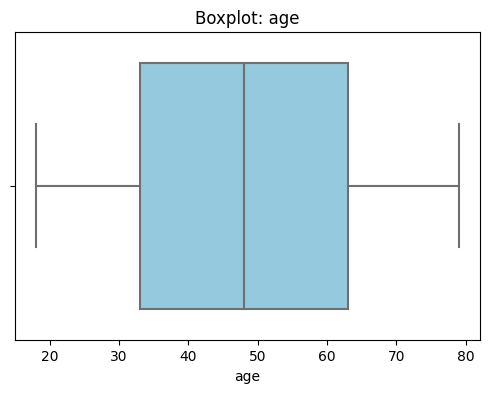

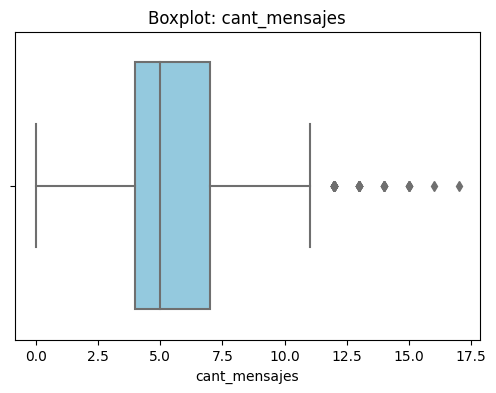

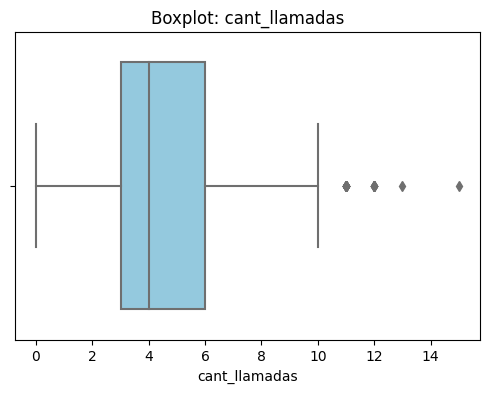

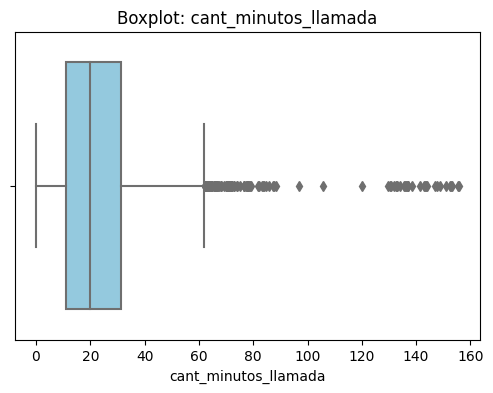

In [388]:
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

def iqr_info(col):
    s = user_profile[col]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return li, ls, int((s > ls).sum()), int((s < li).sum())

for col in columnas_numericas:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=user_profile[col], color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights: 
- Age: ...(presenta o no outliers)
- cant_mensajes: ...
- cant_llamadas: ...
- cant_minutos_llamada: ...

In [389]:
(user_profile['plan'].value_counts(normalize=True) * 100).round(2)

Basico     64.88
Premium    35.12
Name: plan, dtype: float64

In [390]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,23.311225
std,2.359738,2.145139,18.169564
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.107500
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.412500
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
- cant_llamadas: mantener o no outliers, porqué?
- cant_minutos_llamada: mantener o no outliers, porqué?

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [391]:
def insight_plan(col, etiqueta):
    serie = user_profile[col]
    sk = serie.skew()
    forma = 'sesgada a la derecha' if sk > 0.5 else 'sesgada a la izquierda' if sk < -0.5 else 'aproximadamente simétrica'
    por_plan = user_profile.groupby('plan')[col].mean().round(2)
    mayor, menor = por_plan.idxmax(), por_plan.idxmin()
    dif = (por_plan.max() - por_plan.min()) / por_plan.min() * 100 if por_plan.min() > 0 else (100 if por_plan.max() > 0 else 0)
    if dif >= 5:
        patron = f"El plan {mayor} promedia {por_plan.max()} {etiqueta} frente a {por_plan.min()} del plan {menor} ({dif:.1f}% más)."
    else:
        patron = "No existe un patrón claro entre planes (promedios casi iguales)."
    return f"- Distribución {forma} (media {serie.mean():.2f}, mediana {serie.median():.2f}). {patron}"

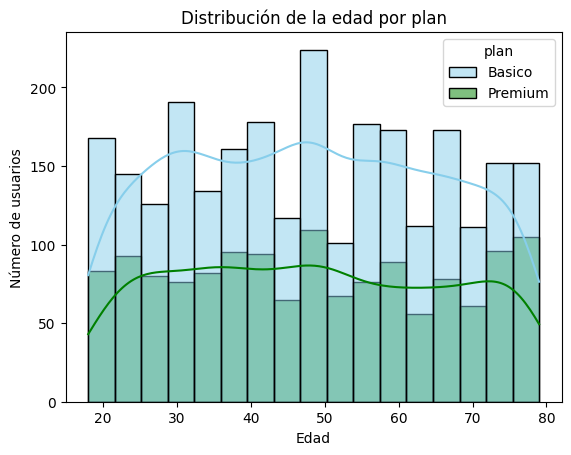

- Distribución aproximadamente simétrica (media 48.14, mediana 48.00). No existe un patrón claro entre planes (promedios casi iguales).


In [392]:

sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue', 'green'], kde=True)
plt.title('Distribución de la edad por plan')
plt.xlabel('Edad')
plt.ylabel('Número de usuarios')
plt.show()
print(insight_plan('age', 'años'))

### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [393]:

user_profile['grupo_edad'] = np.select(
    [user_profile['age'] < 30, user_profile['age'] < 60],
    ['Joven', 'Adulto'],
    default='Adulto Mayor')
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Adulto Mayor


In [394]:
for col in columnas_numericas:
    li, ls, arriba, abajo = iqr_info(col)
    n = arriba + abajo
    if n == 0:
        print(f"- {col}: no presenta outliers.")
    else:
        lado = 'solo hacia arriba' if abajo == 0 else 'solo hacia abajo' if arriba == 0 else 'en ambos lados'
        print(f"- {col}: presenta {n} outliers ({n/len(user_profile)*100:.2f}%), {lado}.")

- age: no presenta outliers.
- cant_mensajes: presenta 46 outliers (1.15%), solo hacia arriba.
- cant_llamadas: presenta 30 outliers (0.75%), solo hacia arriba.
- cant_minutos_llamada: presenta 109 outliers (2.73%), solo hacia arriba.


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

In [395]:
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    li, ls, arriba, abajo = iqr_info(col)
    print(f"{col}: límite superior = {ls:.2f} | máximo = {user_profile[col].max():.2f} | outliers por encima = {arriba}")

user_profile[columnas_limites].describe()

cant_mensajes: límite superior = 11.50 | máximo = 17.00 | outliers por encima = 46
cant_llamadas: límite superior = 10.50 | máximo = 15.00 | outliers por encima = 30
cant_minutos_llamada: límite superior = 61.87 | máximo = 155.69 | outliers por encima = 109


,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,23.311225
std,2.359738,2.145139,18.169564
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.107500
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.412500
max,17.000000,15.000000,155.690000


In [396]:
for col in columnas_limites:
    li, ls, arriba, abajo = iqr_info(col)
    if arriba == 0:
        print(f"- {col}: no hay valores por encima del límite ({ls:.2f}); no hay decisión que tomar.")
    else:
        print(f"- {col}: mantener. {arriba} usuarios superan {ls:.2f} (máximo {user_profile[col].max():.0f}); son valores posibles y no negativos que representan usuarios de uso intensivo con valor comercial. Se marcan para revisión de posible fraude, pero no se eliminan.")

- cant_mensajes: mantener. 46 usuarios superan 11.50 (máximo 17); son valores posibles y no negativos que representan usuarios de uso intensivo con valor comercial. Se marcan para revisión de posible fraude, pero no se eliminan.
- cant_llamadas: mantener. 30 usuarios superan 10.50 (máximo 15); son valores posibles y no negativos que representan usuarios de uso intensivo con valor comercial. Se marcan para revisión de posible fraude, pero no se eliminan.
- cant_minutos_llamada: mantener. 109 usuarios superan 61.87 (máximo 156); son valores posibles y no negativos que representan usuarios de uso intensivo con valor comercial. Se marcan para revisión de posible fraude, pero no se eliminan.



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

In [397]:
mar_duration = usage.groupby('type')['duration'].apply(
    lambda s: s.isna().mean() * 100).round(2)
mar_length = usage.groupby('type')['length'].apply(
    lambda s: s.isna().mean() * 100).round(2)
mar_ok = ((mar_duration.max() - mar_duration.min()) > 50 and
          (mar_length.max() - mar_length.min()) > 50)
user_profile['grupo_uso'] = np.select(
    [(user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
     (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)],
    ['Bajo uso', 'Uso medio'],
    default='Alto uso')

user_profile['grupo_edad'] = np.select(
    [user_profile['age'] < 30, user_profile['age'] < 60],
    ['Joven', 'Adulto'],
    default='Adulto Mayor')
uso_pct = user_profile['grupo_uso'].value_counts(normalize=True)
uso_pct = (uso_pct * 100).round(1)
edad_pct = user_profile['grupo_edad'].value_counts(normalize=True)
edad_pct = (edad_pct * 100).round(1)
cols_m = ['cant_llamadas', 'cant_mensajes']
medias = user_profile.groupby('grupo_edad')[cols_m].mean().round(2)

alto = user_profile[user_profile['grupo_uso'] == 'Alto uso']
alto_plan = alto['plan'].value_counts()
plan_alto = alto_plan.idxmax()
mask = user_profile['plan'] == plan_alto
pct_plan = (user_profile.loc[mask, 'grupo_uso'] == 'Alto uso').mean() * 100

def rango(s):
    return (s.max() - s.min()) / s.mean()

r_edad = rango(user_profile.groupby('grupo_edad')['cant_llamadas'].mean())
r_plan = rango(user_profile.groupby('plan')['cant_llamadas'].mean())
factor = 'la edad' if r_edad > r_plan else 'el plan contratado'

print("⚠️ **Problemas detectados en los datos**")
print(f"- `age`: sentinel -999 en {n_age_sent} filas "
      f"({n_age_sent/n_users*100:.2f}%), reemplazado por la mediana "
      f"({age_mediana:.0f} años).")
print(f"- `city`: sentinel '?' en {n_city_sent} filas "
      f"({n_city_sent/n_users*100:.2f}%), convertido a nulo.")
print(f"- Fechas fuera de rango: {n_reg_fuera} en `reg_date` y "
      f"{n_date_fuera} en `date`, marcadas como nulas.")
if mar_ok:
    print("- `duration` y `length`: nulos por diseño (llamada vs. "
          "mensaje); se dejaron sin imputar.")

print("\n🔍 **Segmentos por edad**")
for g in ['Joven', 'Adulto', 'Adulto Mayor']:
    if g in edad_pct.index:
        ll = medias.loc[g, 'cant_llamadas']
        ms = medias.loc[g, 'cant_mensajes']
        print(f"- {g}: {edad_pct[g]}% de los usuarios; promedio de "
              f"{ll} llamadas y {ms} mensajes.")

print("\n📊 **Segmentos por nivel de uso**")
for g in ['Bajo uso', 'Uso medio', 'Alto uso']:
    if g in uso_pct.index:
        print(f"- {g}: {uso_pct[g]}% de los usuarios.")
print(f"- El plan {plan_alto} concentra más usuarios de Alto uso "
      f"({alto_plan.max()}, el {pct_plan:.1f}% de sus clientes).")

print(f"\n➡️ Esto sugiere que {factor} marca más diferencias en el uso "
      f"de llamadas, y que el grupo de Alto uso "
      f"({uso_pct.get('Alto uso', 0)}%) es el más valioso por su "
      f"consumo y su potencial de ingresos por extras.")

print("\n💡 **Recomendaciones**")
print(f"- Ofrecer a los usuarios de Alto uso del plan {plan_alto} "
      f"una migración a un plan con más minutos o a uno intermedio.")
for col in columnas_limites:
    li, ls, arriba, abajo = iqr_info(col)
    if arriba:
        print(f"- Revisar los {arriba} usuarios atípicos en `{col}` "
              f"(por encima de {ls:.0f}) por posible fraude o error.")
if 'churn' in user_profile.columns:
    mapa = {True: 1, False: 0, 'True': 1, 'False': 0,
            'Yes': 1, 'No': 0, 'yes': 1, 'no': 0, 1: 1, 0: 0}
    cn = user_profile['churn'].map(mapa)
    if cn.notna().any():
        c = cn.groupby(user_profile['grupo_uso']).mean().mul(100).round(1)
        txt = ', '.join(f"{k}: {v}%" for k, v in c.items())
        print(f"- Churn por grupo de uso: {txt}. Priorizar la "
              f"retención en el grupo con mayor churn.")

⚠️ **Problemas detectados en los datos**
- `age`: sentinel -999 en 55 filas (1.38%), reemplazado por la mediana (48 años).
- `city`: sentinel '?' en 96 filas (2.40%), convertido a nulo.
- Fechas fuera de rango: 40 en `reg_date` y 0 en `date`, marcadas como nulas.
- `duration` y `length`: nulos por diseño (llamada vs. mensaje); se dejaron sin imputar.

🔍 **Segmentos por edad**
- Joven: 19.0% de los usuarios; promedio de 4.43 llamadas y 5.52 mensajes.
- Adulto: 50.4% de los usuarios; promedio de 4.48 llamadas y 5.55 mensajes.
- Adulto Mayor: 30.6% de los usuarios; promedio de 4.5 llamadas y 5.49 mensajes.

📊 **Segmentos por nivel de uso**
- Bajo uso: 19.5% de los usuarios.
- Uso medio: 73.6% de los usuarios.
- Alto uso: 7.0% de los usuarios.
- El plan Basico concentra más usuarios de Alto uso (185, el 7.1% de sus clientes).

➡️ Esto sugiere que la edad marca más diferencias en el uso de llamadas, y que el grupo de Alto uso (7.0%) es el más valioso por su consumo y su potencial de ingreso

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- `age`: sentinel -999 en 55 filas (1.38%), reemplazado por la mediana (48 años).
- `city`: sentinel '?' en 96 filas (2.40%), convertido a nulo.
- Fechas fuera de rango: 40 en `reg_date` y 0 en `date`, marcadas como nulas.
- `duration` y `length`: nulos por diseño (llamada vs. mensaje); se dejaron sin imputar.

🔍 **Segmentos por edad**
- Joven: 19.0% de los usuarios; promedio de 4.43 llamadas y 5.52 mensajes.
- Adulto: 50.4% de los usuarios; promedio de 4.48 llamadas y 5.55 mensajes.
- Adulto Mayor: 30.6% de los usuarios; promedio de 4.5 llamadas y 5.49 mensajes.

📊 **Segmentos por nivel de uso**
- Bajo uso: 19.5% de los usuarios.
- Uso medio: 73.6% de los usuarios.
- Alto uso: 7.0% de los usuarios.
- El plan Basico concentra más usuarios de Alto uso (185, el 7.1% de sus clientes).

➡️ Esto sugiere que la edad marca más diferencias en el uso de llamadas, y que el grupo de Alto uso (7.0%) es el más valioso por su consumo y su potencial de ingresos por extras.

💡 **Recomendaciones**
- Ofrecer a los usuarios de Alto uso del plan Basico una migración a un plan con más minutos o a uno intermedio.
- Revisar los 46 usuarios atípicos en `cant_mensajes` (por encima de 12) por posible fraude o error.
- Revisar los 30 usuarios atípicos en `cant_llamadas` (por encima de 10) por posible fraude o error.
- Revisar los 109 usuarios atípicos en `cant_minutos_llamada` (por encima de 62) por posible fraude o error.



---

## 🧩Paso 8 Cargar tu notebook y README a GitHub



🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)



1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---


Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  

- los datasets utilizados,  

- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---





# Análisis ConnectaTel

## 🎯 Objetivo del proyecto
Analizar cómo usan los clientes de ConnectaTel (operaciones en México
y Colombia) los servicios móviles, para identificar patrones de
consumo, detectar comportamientos atípicos y crear segmentos de
clientes que ayuden a mejorar la oferta de planes y la retención.

## 📊 Datasets utilizados
| Archivo | Contenido |
|---|---|
| `plans.csv` | Catálogo de planes: precio, minutos, GB y mensajes incluidos, costo por extra. |
| `users_latam.csv` | Clientes: edad, ciudad, fecha de registro, plan y churn. |
| `usage.csv` | Uso real: llamadas (duración) y mensajes (longitud). |

## 🔄 Etapas del análisis
1. **Carga y exploración** de los tres datasets (estructura y tipos).
2. **Calidad de datos:** nulos, sentinels (`-999` en `age`, `?` en
   `city`) y fechas fuera de rango.
3. **Limpieza:** `age` con la mediana, `city` a nulo y fechas
   imposibles a nulo. Los nulos de `duration` y `length` son MAR
   (dependen de `type`) y se dejaron sin imputar.
4. **Estadísticas de uso por usuario:** mensajes, llamadas y minutos.
5. **Distribuciones y outliers:** histogramas por plan, boxplots y
   método IQR.
6. **Segmentación:** grupos por uso (Bajo, Medio, Alto) y por edad
   (Joven, Adulto, Adulto Mayor).
7. **Insight ejecutivo:** conclusiones y recomendaciones comerciales.

## ▶ Cómo ejecutar el notebook
**Opción A: Google Colab**
1. Abre `analisis_connectatel.ipynb` en este repositorio.
2. Pulsa **Open in Colab**.
3. Sube los tres CSV a Colab (panel de archivos, carpeta `/content/`).
4. En la primera celda cambia las rutas `/datasets/...` por
   `/content/...`.
5. Ejecuta con **Runtime → Run all**.

**Opción B: Jupyter local**
1. Descarga el notebook y los tres CSV en la misma carpeta.
2. Instala las librerías: `pip install pandas numpy seaborn matplotlib`.
3. Cambia las rutas `/datasets/...` por `./`.
4. Abre el notebook y ejecuta todas las celdas.

## 🔁 Guía de reproducción
1. Ejecutar las celdas **en orden, de arriba abajo**. Varias celdas
   dependen de variables creadas antes (`user_profile`, `grupo_uso`,
   `grupo_edad`).
2. Si cambias algo, usa **Restart Kernel and Run All** para evitar
   resultados de ejecuciones anteriores.
3. Requisitos: Python 3, `pandas`, `numpy`, `seaborn` y `matplotlib`.
4. No hay aleatoriedad en el análisis, así que los resultados deben
   ser idénticos con los mismos datos.

## 🛠️ Herramientas
Python, pandas, numpy, seaborn, matplotlib y Jupyter Notebook.

Link a repositorio público del proyecto: `LINK a tu repo aquí`